In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from pde_packages import *

from scipy.sparse import lil_matrix

def create_blank_stgrd_stokes_matrix(N):
    A = lil_matrix(((3*N-1)*(N-1), (3*N-1)*(N-1)))
    return A

def get_U_index(i, j, N):
    if i<0 or i>=N:
        print("Index out of bounds")
        return None
    if j<0.5 or j>=N-0.5:
        print("Index out of bounds. Perhaps you tried to index row 0? U starts at row 0.5.")
        return None
    
    #Make sure the x index is a whole number, and the y index is a half-integer.
    if not float(i).is_integer():
        print("Index out of bounds. i should be a whole number.")
        return None
    if not (j - 0.5).is_integer():
        print("Index out of bounds. j should be a half-integer.")
        return None
    
    #our x is going to be the fast index. Like reading a book row by row.
    return int(i + N * (j - 0.5))

def get_V_index(i, j, N):
    if i<0.5 or i>=N-0.5:
        raise ValueError("i index out of bounds for V grid")
    if j<0 or j>=N:
        raise ValueError("j index out of bounds for V grid")

    if not (i-0.5).is_integer():
        raise ValueError("i index must be a half-integer for V grid")
    if not j.is_integer():
        raise ValueError("j index must be an integer for V grid")

    return int((i-0.5) + (N-1)*j) + N*(N-1)

def get_P_index(i, j, N):
    if i<0.5 or i>=N-0.5:
        print("Index out of bounds. Perhaps you tried to index column 0? P starts at column 0.5.")
        return None
    if j<0.5 or j>=N-0.5:
        print("Index out of bounds. Perhaps you tried to index row 0? P starts at row 0.5.")
        return None

    if not (j-0.5).is_integer():
        print("Index out of bounds. P indices must be half-integers.")
        return None
    if not (i-0.5).is_integer():
        print("Index out of bounds. P indices must be half-integers.")
        return None

    return int(i-0.5 + (j-0.5)*(N-1)) + 2*N*(N-1)

def get_xy(i, j, N, x_0, x_N, y_0, y_N):
    x = x_0 + i * (x_N - x_0) / (N-1)
    y = y_0 + j * (y_N - y_0) / (N-1)
    return x, y

def laplacian_U(A, N, h, b, grad_squared_U, dxP, x_0, x_N, y_0, y_N, tpbdy, bmbdy):
    for j in range(0, N-1):
        #j for U are the 1/2 grid points.
        j+=0.5
        for i in range(0, N):

            #We should be using this no matter what:
            self_U_index = get_U_index(i, j, N)

            #If it's the very last column, we just set it equal to the value for the first column and continue.
            if i == N-1:
                A[self_U_index, self_U_index] = 1.0
                A[self_U_index, get_U_index(0, j, N)] = -1.0
                b[self_U_index] = 0.0
                continue

            A[self_U_index, self_U_index] += -4.0/h**2
            [x,y] = get_xy(i, j, N, x_0, x_N, y_0, y_N)
            b[self_U_index] =  grad_squared_U(x, y) - dxP(x,y)

            if i == 0:
                # Apply boundary condition for the left boundary of U
                # We don't do ghost points here, we do periodic conditions instead. So the i-1 index (outside of domain) wraps around to the last index.
                A[self_U_index, get_U_index(N-2, j, N)] = 1.0/h**2   #Left side value, wrapped around.
                A[self_U_index, get_U_index(i+1, j, N)] = 1.0/h**2   #Right side value, normal.
            else:
                A[self_U_index, get_U_index(i-1, j, N)] = 1.0/h**2
                A[self_U_index, get_U_index(i+1, j, N)] = 1.0/h**2
            
            # if j == 0.5:
            #     # Apply boundary condition for the bottom boundary of U
            #     #Note that the laplacian will still really describe this equation,
            #     #We just use a ghost point as one of the neighboring points in the laplacian.
            #     #Specifically, on the opposite side of the boundary, (u_self + u_ghost)/2 represents the value at the boundary.
            #     #Therefore, run the same laplacian as for the interior points, u_G becomes:
            #     #2(bdy - u_self) where 2*bdy goes to the rhs (b)
            #     A[self_U_index, self_U_index] -= 1.0/h**2
            #     b[self_U_index] += -2*bmbdy(x, y)/h**2
            #     A[self_U_index, get_U_index(i, j+1, N)] = 1.0/h**2
            # elif j == N-1.5:
            #     # Apply boundary condition for the top boundary of U
            #     A[self_U_index, get_U_index(i, j-1, N)] = 1.0/h**2
            #     A[self_U_index, self_U_index] -= 1.0/h**2
            #     b[self_U_index] += -2*tpbdy(x, y)/h**2

            if j == 0.5:
                A[self_U_index, self_U_index] += -3.0/h**2
                A[self_U_index, get_U_index(i, j+1, N)] = 2.0/h**2
                A[self_U_index, get_U_index(i, j+2, N)] = -(1/5)/h**2

                [x_bdy, y_bdy] = get_xy(i, 0, N, x_0, x_N, y_0, y_N)
                b[self_U_index] += -(16/5)*bmbdy(x_bdy, y_bdy)/h**2

            elif j == N-1.5:
                A[self_U_index, self_U_index] += -3.0/h**2
                A[self_U_index, get_U_index(i, j-1, N)] = 2.0/h**2
                A[self_U_index, get_U_index(i, j-2, N)] = -(1/5)/h**2

                [x_bdy, y_bdy] = get_xy(i, N-1, N, x_0, x_N, y_0, y_N)
                b[self_U_index] += -(16/5)*tpbdy(x_bdy, y_bdy)/h**2


            else:
                A[self_U_index, get_U_index(i, j-1, N)] = 1.0/h**2
                A[self_U_index, get_U_index(i, j+1, N)] = 1.0/h**2

            #Now we need to get the neighboring P indices for the current U point.
            if i == 0:
                A[self_U_index, get_P_index(N-1.5, j, N)] = 1.0/(h)
                A[self_U_index, get_P_index(i+0.5, j, N)] = -1.0/(h)
            # elif i == N-1:
            #     A[self_U_index, get_P_index(i-0.5, j, N)] = 1.0/(h)
            #     A[self_U_index, get_P_index(0.5, j, N)] = -1.0/(h)
            else:
                A[self_U_index, get_P_index(i-0.5, j, N)] = 1.0/(h)
                A[self_U_index, get_P_index(i+0.5, j, N)] = -1.0/(h)

def laplacian_V(A, N, h, b, grad_squared_V, dyP, x_0, x_N, y_0, y_N, tpbdy, bmbdy):
    for j in range(0, N):
        for i in range(0, N-1):
            i+=0.5
            self_V_index = get_V_index(i, j, N)
            [x,y] = get_xy(i, j, N, x_0, x_N, y_0, y_N)

            if j == 0:
                A[self_V_index, self_V_index] = 1
                b[self_V_index] = bmbdy(x, y)
            elif j == N-1:
                A[self_V_index, self_V_index] = 1
                b[self_V_index] = tpbdy(x, y)

            else:
                A[self_V_index, self_V_index] = -4.0/h**2
                [x,y] = get_xy(i, j, N, x_0, x_N, y_0, y_N)
                b[self_V_index] = grad_squared_V(x, y) - dyP(x, y)

                if i == 0.5:
                    A[self_V_index, get_V_index(N-1.5, j, N)] = 1.0/h**2
                    A[self_V_index, get_V_index(i+1, j, N)] = 1.0/h**2
                elif i == N-1.5:
                    A[self_V_index, get_V_index(i-1, j, N)] = 1.0/h**2
                    A[self_V_index, get_V_index(0.5, j, N)] = 1.0/h**2
                else:
                    A[self_V_index, get_V_index(i-1, j, N)] = 1.0/h**2
                    A[self_V_index, get_V_index(i+1, j, N)] = 1.0/h**2

                A[self_V_index, get_V_index(i, j-1, N)] = 1.0/h**2
                A[self_V_index, get_V_index(i, j+1, N)] = 1.0/h**2

                A[self_V_index, get_P_index(i, j-0.5, N)] = 1.0/(h)
                A[self_V_index, get_P_index(i, j+0.5, N)] = -1.0/(h)

def divergence(A, N, h, b):
    for j in range(0, N-1):
        j+=0.5
        for i in range(0, N-1):
            i+=0.5
            self_P_index = get_P_index(i, j, N)

            A[self_P_index, get_U_index(i+0.5, j, N)] = 1.0/(h)
            A[self_P_index, get_U_index(i-0.5, j, N)] = -1.0/(h)
            A[self_P_index, get_V_index(i, j+0.5, N)] = 1.0/(h)
            A[self_P_index, get_V_index(i, j-0.5, N)] = -1.0/(h)

            b[self_P_index] = 0

def test_gsU(x, y):
    return -8*np.pi**2*np.sin(2*np.pi*x)*np.sin(2*np.pi*y)

def test_gsV(x, y):
    return -4*np.pi**2*np.cos(2*np.pi*x)*(2*np.cos(2*np.pi*y)-1)

def test_dxP(x, y):
    return -2*np.pi*np.sin(2*np.pi*x)*np.sin(2*np.pi*y)

def test_dyP(x, y):
    return 2*np.pi*np.cos(2*np.pi*x)*np.cos(2*np.pi*y)

def test_tpbdy_U(x, y):
    return 0
def test_bmbdy_U(x, y):
    return 0

def test_tpbdy_V(x, y):
    return -3.5
def test_bmbdy_V(x, y):
    return -3.5

def break_uvp(x, N):
    assert len(x) == (3*N-1)*(N-1), "Error breaking into uvp expected different sized x"
    u = x[:(N-1)*N]
    v = x[(N-1)*N:2*(N-1)*N]
    p = x[2*(N-1)*N:]
    return u, v, p

def test_Uxy(x,y):
    return np.sin(2*np.pi*x)*np.sin(2*np.pi*y)

def test_Vxy(x,y):
    return -3.5 + np.cos(2*np.pi*x)*(np.cos(2*np.pi*y)-1)

def test_Pxy(x,y):
    return np.sin(2*np.pi*y)*np.cos(2*np.pi*x)

def get_real_U(x_real, N, U_func, x_0, x_N, y_0, y_N):
    for j in range(0, N-1):
        j += 0.5
        for i in range(0, N):
            self_U_index = get_U_index(i, j, N)
            x, y = get_xy(i, j, N, x_0, x_N, y_0, y_N)
            x_real[self_U_index] = U_func(x, y)
    return x_real

def get_real_V(x_real, N, V_func, x_0, x_N, y_0, y_N):
    for j in range(0,N):
        for i in range(0, N-1):
            i += 0.5
            self_V_index = get_V_index(i, j, N)
            x, y = get_xy(i, j, N, x_0, x_N, y_0, y_N)
            x_real[self_V_index] = V_func(x, y)
    return x_real

def get_real_P(x_real, N, P_func, x_0, x_N, y_0, y_N):
    for j in range(0, N-1):
        j += 0.5
        for i in range(0, N-1):
            i += 0.5
            self_P_index = get_P_index(i, j, N)
            x, y = get_xy(i, j, N, x_0, x_N, y_0, y_N)
            x_real[self_P_index] = P_func(x, y)
    return x_real

def interpret_x_for_graph(x, N):
    u = np.zeros((N-1, N-1))
    v = np.zeros((N-1, N-1))
    p = np.zeros((N-1, N-1))

    for j in range(0,N-1):
        j+=0.5
        for i in range(0,N-1):
            i+=0.5
            #Here we will interpolate to give the value of u and v at the midpoint of each cell.
            U_mid = (x[get_U_index(i-0.5, j, N)] + x[get_U_index(i+0.5, j, N)]) / 2
            V_mid = (x[get_V_index(i, j-0.5, N)] + x[get_V_index(i, j+0.5, N)]) / 2
            P = x[get_P_index(i, j, N)]
            #Here we could store or return U_mid and V_mid as needed
            u[int(j-0.5), int(i-0.5)] = U_mid
            v[int(j-0.5), int(i-0.5)] = V_mid
            p[int(j-0.5), int(i-0.5)] = P

    return u, v, p

In [2]:
N_vals = [6,11,26,51,101,251]
err_vals = [] 
U_ap_vals = []
V_ap_vals = []
P_ap_vals = []
col_x_vals = []
OhNn1_vals = []
OhNn2_vals = []

x_0, x_N, y_0, y_N = 0, 1, 0, 1

for N in N_vals:
    h = (x_N - x_0)/(N-1)
    A = create_blank_stgrd_stokes_matrix(N)
    b = np.zeros(A.shape[0])
    laplacian_U(A, N, h, b, test_gsU, test_dxP, x_0, x_N, y_0, y_N, test_tpbdy_U, test_bmbdy_U)
    laplacian_V(A, N, h, b, test_gsV, test_dyP, x_0, x_N, y_0, y_N, test_tpbdy_V, test_bmbdy_V)
    divergence(A, N, h, b)

    x = sp.sparse.linalg.spsolve(A.tocsr(), b)

    U_ap, V_ap, P_ap = break_uvp(x, N)
    P_ap -= np.mean(P_ap)
    U_ap_vals.append(U_ap)
    V_ap_vals.append(V_ap)
    P_ap_vals.append(P_ap)
    col_x_vals.append(x)

    x_real = np.zeros_like(x)

    x_real = get_real_U(x_real, N, test_Uxy, x_0, x_N, y_0, y_N)
    x_real = get_real_V(x_real, N, test_Vxy, x_0, x_N, y_0, y_N)
    x_real = get_real_P(x_real, N, test_Pxy, x_0, x_N, y_0, y_N)

    U_rl, V_rl, P_rl = break_uvp(x_real, N)

    err_U = np.linalg.norm(U_ap - U_rl)/np.linalg.norm(U_rl)
    err_V = np.linalg.norm(V_ap - V_rl)/np.linalg.norm(V_rl)
    err_P = np.linalg.norm(P_ap - P_rl)/np.linalg.norm(P_rl)
    print(f"N = {N}: err_U = {err_U}, err_V = {err_V}, err_P = {err_P}")
    err_vals.append((err_U, err_V, err_P))

    OhNn1_vals.append(1/N)
    OhNn2_vals.append(1/N**2)

# Convert err_vals to a NumPy array for easier plotting
err_vals = np.array(err_vals)




N = 6: err_U = 0.1357976449471654, err_V = 0.028052737407630715, err_P = 0.48725012363398024
N = 11: err_U = 0.033464893198861444, err_V = 0.007569559697245122, err_P = 0.032030168692107105
N = 26: err_U = 0.0052800830507687985, err_V = 0.0012435730588596758, err_P = 0.0027644861175804025
N = 51: err_U = 0.0013169786004934684, err_V = 0.0003133430374438372, err_P = 0.0006621261219926943
N = 101: err_U = 0.0003290515300380324, err_V = 7.866441003011219e-05, err_P = 0.00016463203608834022
N = 251: err_U = 5.2639550010507586e-05, err_V = 1.2619834928422851e-05, err_P = 2.6320637498428885e-05


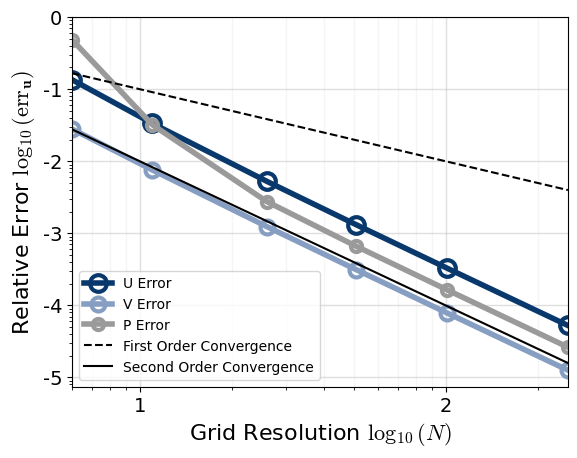

In [6]:
mines_silver = "#9A9A9A"

plt.rcParams['mathtext.fontset'] = 'cm'

plt.loglog(N_vals, err_vals[:,0], label='U Error', color=blaster_blue, linewidth=4, marker='o', markersize=12, markeredgewidth=3, markerfacecolor='none')
plt.loglog(N_vals, err_vals[:,1], label='V Error', color=light_blue, linewidth=4, marker='o', markersize=10, markeredgewidth=3, markerfacecolor='none')
plt.loglog(N_vals, err_vals[:,2], label='P Error', color=mines_silver, linewidth=4, marker='o', markersize=8, markeredgewidth=3, markerfacecolor='none')
plt.xlabel(r"Grid Resolution $\log_{10}(N)$", fontsize=16)
plt.loglog(N_vals, OhNn1_vals, label='First Order Convergence', linestyle='--', color='black')
plt.loglog(N_vals, OhNn2_vals, label='Second Order Convergence', color='black')
plt.ylabel(r"Relative Error $\log_{10}(\text{err}_\mathbf{u})$", fontsize=16)
plt.xlim([min(N_vals), max(N_vals)])
plt.grid(True, which="major", linewidth=1, alpha=0.5, color='silver')
plt.grid(True, which="minor", linewidth=1, alpha=0.15, color='silver')
plt.grid(False, axis="y", which="minor")
plt.xticks([10, 100], ['1', '2'], fontsize=14)
plt.yticks([1e0, 1e-1, 1e-2, 1e-3, 1e-4, 1e-5], ['0', '-1', '-2', '-3', '-4', '-5'], fontsize=14)
plt.legend()

plt.savefig("stokes_error_plot.png", bbox_inches='tight')
plt.show()


Notes on redefining incorporation of ghost point interpolant on top, bottom boundaries for u:


Begin with a cubic interpolant:
$$
    \begin{aligned}
    p(s) &= \sum_{k=0}^{3} u_k L_k(s), \\
    L_k(s) &= \prod_{\substack{m=0 \\ m\neq k}}^{3}
    \frac{s-s_m}{s_k-s_m}.
    \end{aligned}
$$

Where
$$
    \begin{aligned}
    s &= y/h, \\
    L_0(-1/2) &= \frac{(-1)(-2)(-3)}{(-1/2)(-3/2)(-5/2)} = \frac{16}{5} , \\
    L_1(-1/2) &= \cdots = -3, \quad \text{(exercise left to reader)} \\
    L_2(-1/2) &= \cdots = 1, \\
    L_3(-1/2) &=  \cdots = -\frac{1}{5} \\
    \end{aligned}
$$

Therefore
$$
    \begin{aligned}
    u_{i,-0.5} &= \frac{16}{5}u_{i,0}-3u_\text{i,0.5}+u_{i,1.5}-\frac{1}{5}u_{i,2.5} + O(h^4), \\
    u_yy_{i, 0.5} &= \frac{\frac{16}{5}u_{i,0} - 5u_{i,0.5} + 2u_{i,1.5}-\frac{1}{5}u_{i,2.5}}{h^2} + \frac{O(h^4)}{h^2}  + O(h^2) \\
    \nabla^2u_{i,0.5} &= \frac{\frac{16}{5}u_{i,0} - 7u_{i,0.5} + 2u_{i,1.5}-\frac{1}{5}u_{i,2.5} + u_{i-1,0.5} + u_{i+1,0.5}}{h^2} + O(h^2) 
    \end{aligned}
$$